# Figures 6 and 10: negative curvature in truncated Newton methods

This notebook draws the figures of the truncated Newton experiment (Section 2.2.2 and the appendix) of

> G. Fasano, C. Piermarini, M. Roma. *Benchmarking Optimization Algorithms with Quality Profiles.* Mathematical Programming Computation (accepted), [arXiv:2607.16798](https://arxiv.org/abs/2607.16798).

Each figure uses the same results and the same parameters `r1` and `r2` as the MATLAB script of the [reference repository](https://github.com/fasano-g/Quality-Profiles) that produced it, so the two implementations can be compared side by side. The MATLAB scripts all start with `r1 = 1; r2 = 1;` (line 186): to reproduce a figure with different values, set them there.

| Figure | Test set | `r1` | `r2` | MATLAB script |
| --- | --- | --- | --- | --- |
| 6 | 166 problems | 1 | 1 | `Profiles_N_codes_v3_github_revised_Figure_6.m` |
| 10 | 45 problems with n = 10000 | 1 | 1 | `Profiles_N_codes_v3_github_revised_Figure_10_n_10000.m` |

The results are read from `examples/data` (see [`examples/data/README.md`](../examples/data/README.md)). The colors fade from red to blue as in the paper (`colors="paper"`). The profiles are drawn as step functions, their exact shape; the MATLAB figures join the grid points with straight segments instead, which shows as slanted lines where the grid is sparse. Pass `steps=False` to `draw` to get the same look.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt

from quality_profiles import plot_quality_profiles, quality_profiles

# The results of the paper are in examples/data; examples/utils/paper_data.py reads them.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "examples" / "data").is_dir())
sys.path.insert(0, str(ROOT / "examples"))
from utils.paper_data import load  # noqa: E402

plt.rcParams["figure.dpi"] = 110


def draw(
    figure, dataset, r1=1, r2=1, n=None, ax=None, legend=True, legend_loc="lower right", steps=True
):
    """Compute and plot the quality profiles of one figure of the paper.

    steps=False joins the grid points with straight segments, as the MATLAB figures do.
    """
    f0, f_solvers, names = load(dataset, n=n)
    qp = quality_profiles(f0, f_solvers, solver_names=names, r1=r1, r2=r2)
    title = f"{figure}: |S| = {len(names)}, |P| = {len(f0)}, r1 = {r1}, r2 = {r2}"
    plot_quality_profiles(
        qp, ax, colors="paper", title=title, legend=legend, legend_loc=legend_loc, steps=steps
    )
    return qp


def table(qp, levels=(1, 1e-1, 1e-3, 1e-6, 1e-9, 1e-12)):
    """Print the profiles at a few precision levels."""
    print(f"{'precision':>10s}" + "".join(f"{name:>14s}" for name in qp.solver_names))
    for level, row in zip(levels, qp.evaluate(levels), strict=True):
        print(f"{level:>10.0e}" + "".join(f"{value:>14.3f}" for value in row))

## Figure 6

Weak quality profiles of four truncated Newton variants, which differ in how they use negative curvature directions, on 166 CUTEst problems, with `r1 = 1` and `r2 = 1`.

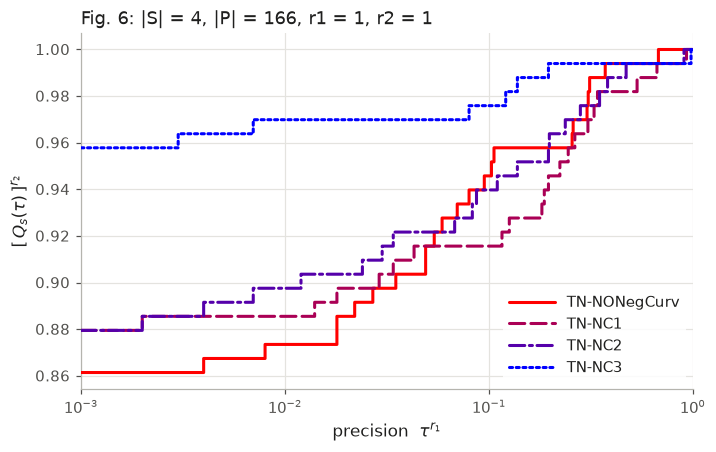

In [2]:
qp = draw("Fig. 6", "negative_curvature", r1=1, r2=1)
plt.show()

In [3]:
table(qp, levels=(1, 1e-1, 1e-2, 1e-3))

 precision  TN-NONegCurv        TN-NC1        TN-NC2        TN-NC3
     1e+00         1.000         1.000         1.000         1.000
     1e-01         0.946         0.916         0.940         0.976
     1e-02         0.873         0.886         0.898         0.970
     1e-03         0.861         0.880         0.880         0.958


## Figure 10

As Figure 6, on the 45 problems with dimension $n = 10{,}000$ only.

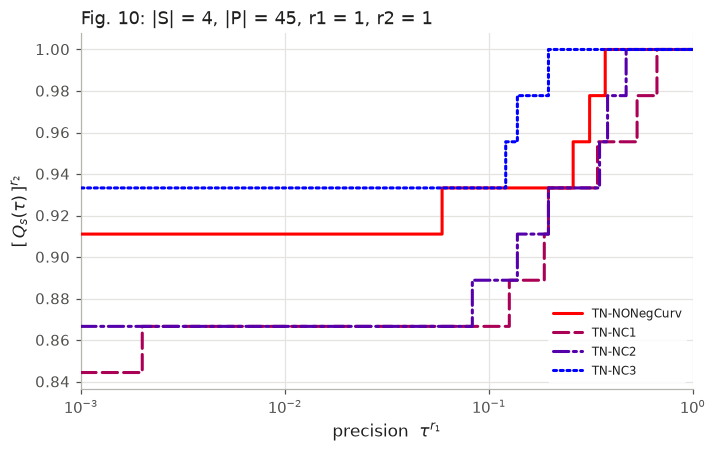

In [4]:
draw("Fig. 10", "negative_curvature", r1=1, r2=1, n=10000)

# A smaller legend, so that it does not cover the curves of TN-NC1 and TN-NC2.
ax = plt.gca()
ax.legend(
    handles=ax.get_legend().legend_handles,
    loc="lower right",
    fontsize=8,
    handlelength=2.4,
    facecolor="white",
    edgecolor="none",
    framealpha=0.85,
    labelcolor="#1f1f1e",
)
plt.show()